In [ ]:
# Google Colab : télécharger les données de cette séance / download this session's data
import os, urllib.request
BASE = "https://raw.githubusercontent.com/Marzoug-Nabil/Nabil/main/academic/teaching/fsci6222/materials/tp1/"
for f in ['departements_info.csv', 'employes_techno.csv']:
    os.makedirs('data', exist_ok=True)
    for dst in (f, os.path.join('data', f)):
        if not os.path.exists(dst):
            urllib.request.urlretrieve(BASE + f, dst)


# FSCI 6222 — TP1 Partie 2 — CORRIGÉ
## Statistiques descriptives

---

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')

### Préparation : nettoyage des données

In [3]:
# Chargement et nettoyage (repris de la Partie 1)
df = pd.read_csv('data/employes_techno.csv')

# NaN
df['salaire'] = df['salaire'].fillna(df['salaire'].median())
df['annees_experience'] = df['annees_experience'].fillna(df['annees_experience'].median())
df['note_evaluation'] = df['note_evaluation'].fillna(df['note_evaluation'].mean())

# Doublons
df = df.drop_duplicates()

# Types
df['heures_formation'] = df['heures_formation'].replace('deux', '2')
df['heures_formation'] = pd.to_numeric(df['heures_formation'])
df['date_embauche'] = pd.to_datetime(df['date_embauche'], errors='coerce')

# Texte
df['ville'] = df['ville'].str.capitalize()
df['type_contrat'] = df['type_contrat'].str.capitalize()

# Outliers
df.loc[df['heures_formation'] < 0, 'heures_formation'] = np.nan
df['heures_formation'] = df['heures_formation'].fillna(df['heures_formation'].median())
df.loc[df['salaire'] > 1000000, 'salaire'] = 65000

print(f"Dataset nettoyé : {df.shape}")

Dataset nettoyé : (42, 16)


In [12]:
df.head()

,id,nom,prenom,departement,poste,ville,salaire,annees_experience,heures_formation,nb_projets,note_evaluation,satisfaction,age,sexe,type_contrat,date_embauche
0,1,Tremblay,Sophie,Développement,Développeuse Senior,Moncton,82000.0,8.0,45.0,12,4.5,5,34,F,Permanent,2018-03-15
1,2,Landry,Marc,Données,Analyste Junior,Dieppe,52000.0,2.0,20.0,4,3.2,3,26,M,Permanent,2024-01-10
2,3,Cormier,Julie,Développement,Développeuse Junior,Moncton,55000.0,1.0,35.0,3,3.8,4,24,F,Contractuel,2025-02-01
3,4,LeBlanc,Pierre,Infrastructure,Administrateur Système,Fredericton,68000.0,5.0,30.0,8,4.0,4,32,M,Permanent,2021-06-20
4,5,Richard,Anne,Données,Scientifique de données,Moncton,95000.0,10.0,60.0,18,4.8,5,38,F,Permanent,2016-09-01


---
## Q1 — Tendance centrale (12 pts)
### 1.1 Calculs de base (6 pts)

In [4]:
# a) Moyenne, médiane, mode (2 pts)
moyenne = df['salaire'].mean()
mediane = df['salaire'].median()
mode = df['salaire'].mode()[0]

print(f"Moyenne : {moyenne:,.2f}$")
print(f"Médiane : {mediane:,.2f}$")
print(f"Mode    : {mode:,.2f}$")

# b) Interprétation (2 pts)
if moyenne > mediane:
    print(f"\nMoyenne ({moyenne:,.0f}) > Médiane ({mediane:,.0f})")
    print("→ Asymétrie positive : quelques salaires élevés tirent la moyenne vers le haut")
else:
    print(f"\nMoyenne ({moyenne:,.0f}) < Médiane ({mediane:,.0f})")
    print("→ Asymétrie négative : quelques salaires bas tirent la moyenne vers le bas")

# c) Par département (2 pts)
stats_dept = df.groupby('departement')['salaire'].agg(['mean', 'median']).round(0)
stats_dept['diff'] = (stats_dept['mean'] - stats_dept['median']).abs()
print(f"\nStatistiques par département :")
print(stats_dept)
print(f"\nPlus grande différence : {stats_dept['diff'].idxmax()} ({stats_dept['diff'].max():,.0f}$)")
print("→ Probablement dû à un ou plusieurs salaires extrêmes dans ce département")

Moyenne : 71,000.00$
Médiane : 71,000.00$
Mode    : 72,000.00$

Moyenne (71,000) < Médiane (71,000)
→ Asymétrie négative : quelques salaires bas tirent la moyenne vers le bas

Statistiques par département :
                   mean   median    diff
departement                             
Données         74182.0  72000.0  2182.0
Développement   70286.0  70000.0   286.0
Infrastructure  74400.0  74000.0   400.0
Marketing       62571.0  58000.0  4571.0

Plus grande différence : Marketing (4,571$)
→ Probablement dû à un ou plusieurs salaires extrêmes dans ce département


**Barème 1.1 :** Calculs corrects 2pts, interprétation moyenne vs médiane 2pts, par département + explication 2pts

### 1.2 Impact des outliers (6 pts)

Sans PDG : moyenne = 71,000$, médiane = 71,000$
Avec PDG : moyenne = 80,977$, médiane = 72,000$

Variation moyenne  : +14.1%
Variation médiane  : +1.4%

→ La moyenne est beaucoup plus affectée (14.1% vs 1.4%)
→ La médiane est robuste aux outliers


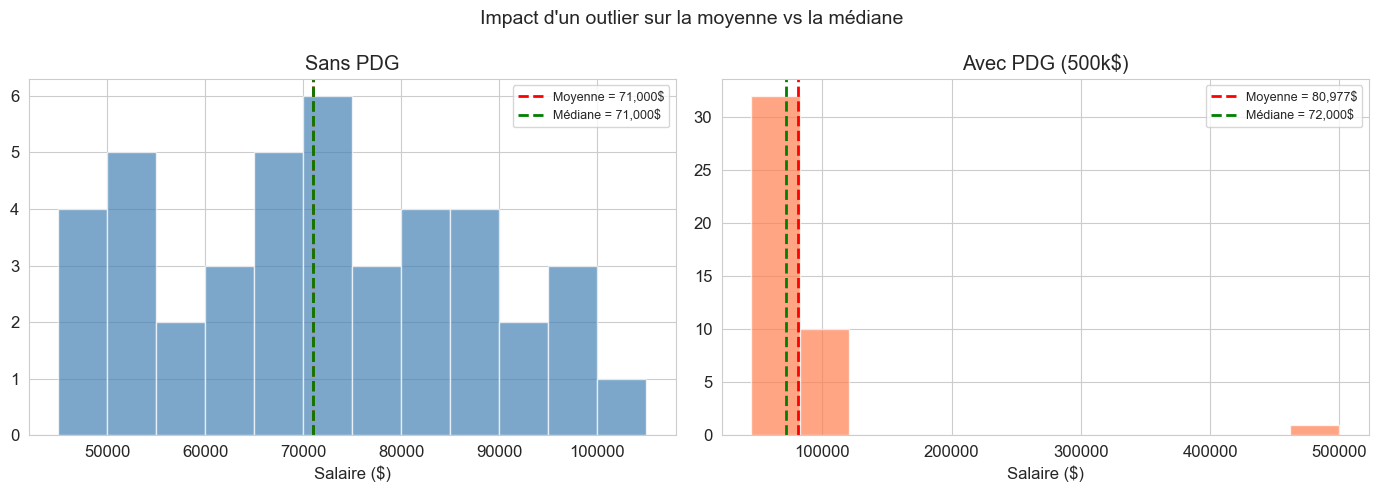

In [5]:
# a) Ajouter un PDG (2 pts)
df_copie = df.copy()
pdg = pd.DataFrame({
    'nom': ['PDG'],
    'prenom': ['Fictif'],
    'departement': ['Direction'],
    'salaire': [500000],
    'annees_experience': [20],
    'ville': ['Moncton']
}, index=[0])
df_avec_pdg = pd.concat([df_copie, pdg], ignore_index=True)

moy_sans = df['salaire'].mean()
med_sans = df['salaire'].median()
moy_avec = df_avec_pdg['salaire'].mean()
med_avec = df_avec_pdg['salaire'].median()

print(f"Sans PDG : moyenne = {moy_sans:,.0f}$, médiane = {med_sans:,.0f}$")
print(f"Avec PDG : moyenne = {moy_avec:,.0f}$, médiane = {med_avec:,.0f}$")

# b) Variation en pourcentage (2 pts)
var_moy = ((moy_avec - moy_sans) / moy_sans) * 100
var_med = ((med_avec - med_sans) / med_sans) * 100

print(f"\nVariation moyenne  : +{var_moy:.1f}%")
print(f"Variation médiane  : +{var_med:.1f}%")
print(f"\n→ La moyenne est beaucoup plus affectée ({var_moy:.1f}% vs {var_med:.1f}%)")
print("→ La médiane est robuste aux outliers")

# c) Visualisation côte à côte (2 pts)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['salaire'], bins=12, color='steelblue', edgecolor='white', alpha=0.7)
axes[0].axvline(x=moy_sans, color='red', linestyle='--', linewidth=2, label=f'Moyenne = {moy_sans:,.0f}$')
axes[0].axvline(x=med_sans, color='green', linestyle='--', linewidth=2, label=f'Médiane = {med_sans:,.0f}$')
axes[0].set_title('Sans PDG')
axes[0].set_xlabel('Salaire ($)')
axes[0].legend(fontsize=9)

axes[1].hist(df_avec_pdg['salaire'], bins=12, color='coral', edgecolor='white', alpha=0.7)
axes[1].axvline(x=moy_avec, color='red', linestyle='--', linewidth=2, label=f'Moyenne = {moy_avec:,.0f}$')
axes[1].axvline(x=med_avec, color='green', linestyle='--', linewidth=2, label=f'Médiane = {med_avec:,.0f}$')
axes[1].set_title('Avec PDG (500k$)')
axes[1].set_xlabel('Salaire ($)')
axes[1].legend(fontsize=9)

plt.suptitle('Impact d\'un outlier sur la moyenne vs la médiane', fontsize=14)
plt.tight_layout()
plt.show()

---
## Q2 — Dispersion (12 pts)
### 2.1 Calcul manuel (6 pts)

In [6]:
# a) Calcul pas à pas (4 pts)
salaires = df['salaire']
n = len(salaires)

# 1. Moyenne
moyenne = salaires.sum() / n
print(f"1. Moyenne : {moyenne:,.2f}$")

# 2. Écarts à la moyenne
ecarts = salaires - moyenne
print(f"\n2. Écarts (5 premiers) : {ecarts.head().round(2).tolist()}")

# 3. Écarts au carré
ecarts_carres = ecarts ** 2
print(f"3. Écarts² (5 premiers) : {ecarts_carres.head().round(2).tolist()}")

# 4. Variance
variance = ecarts_carres.sum() / (n - 1)
print(f"\n4. Variance : {variance:,.2f}")

# 5. Écart-type
ecart_type = np.sqrt(variance)
print(f"5. Écart-type : {ecart_type:,.2f}$")

# b) Vérification (1 pt)
print(f"\nVérification pandas :")
print(f"   Variance   : {salaires.var():,.2f}")
print(f"   Écart-type : {salaires.std():,.2f}")

# c) CV (1 pt)
for col in ['salaire', 'heures_formation', 'nb_projets']:
    cv = (df[col].std() / df[col].mean()) * 100
    print(f"CV {col:20} : {cv:.1f}%")
print("→ La variable avec le CV le plus élevé est la plus dispersée relativement")

1. Moyenne : 71,000.00$

2. Écarts (5 premiers) : [11000.0, -19000.0, -16000.0, -3000.0, 24000.0]
3. Écarts² (5 premiers) : [121000000.0, 361000000.0, 256000000.0, 9000000.0, 576000000.0]

4. Variance : 253,170,731.71
5. Écart-type : 15,911.34$

Vérification pandas :
   Variance   : 253,170,731.71
   Écart-type : 15,911.34
CV salaire              : 22.4%
CV heures_formation     : 47.9%
CV nb_projets           : 54.8%
→ La variable avec le CV le plus élevé est la plus dispersée relativement


### 2.2 Comparaison entre départements (6 pts)

                count      mean   median       std      min       max     CV
departement                                                                 
Données            11  74181.82  72000.0  18043.38  50000.0   96000.0  24.32
Développement      14  70285.71  70000.0  14625.73  48000.0  105000.0  20.81
Infrastructure     10  74400.00  74000.0  14930.95  45000.0   98000.0  20.07
Marketing           7  62571.43  58000.0  16359.07  46000.0   88000.0  26.14


/var/folders/8z/3v_z80_10qq6rtk0_b4cbx200000gn/T/ipykernel_15080/493992630.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='departement', y='salaire', palette='Set2')


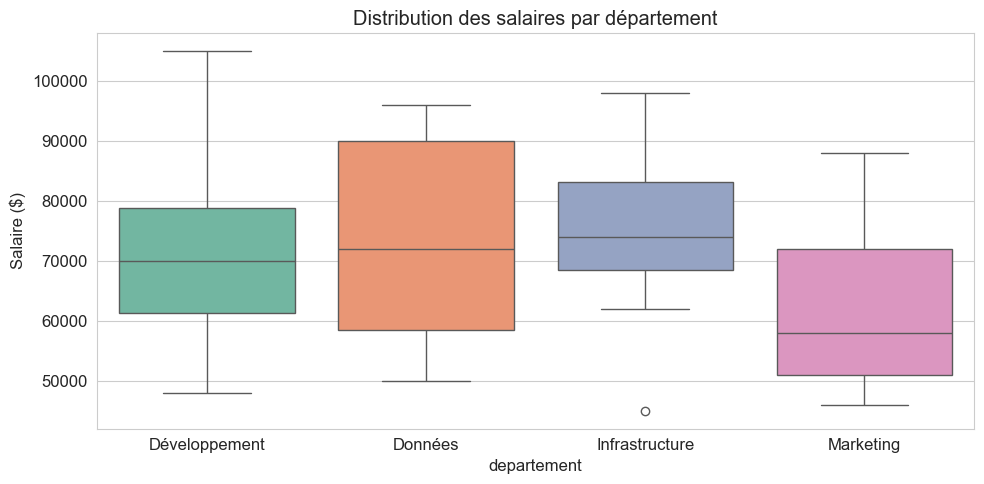


IQR par département :
  Développement        : IQR = 17,500$ (Q1=61,250, Q3=78,750)
  Données              : IQR = 31,500$ (Q1=58,500, Q3=90,000)
  Infrastructure       : IQR = 14,750$ (Q1=68,500, Q3=83,250)
  Marketing            : IQR = 21,000$ (Q1=51,000, Q3=72,000)

→ Le département avec le plus grand IQR est le plus dispersé
→ Le département avec le plus petit IQR est le plus homogène


In [7]:
# a) DataFrame résumé (3 pts)
def cv_func(x):
    return (x.std() / x.mean()) * 100

resume = df.groupby('departement')['salaire'].agg(
    count='count',
    mean='mean',
    median='median',
    std='std',
    min='min',
    max='max',
    CV=cv_func
).round(2)
print(resume)

# b) Boxplot + IQR (3 pts)
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='departement', y='salaire', palette='Set2')
plt.title('Distribution des salaires par département')
plt.ylabel('Salaire ($)')
plt.tight_layout()
plt.show()

print("\nIQR par département :")
for dept in df['departement'].unique():
    data = df[df['departement'] == dept]['salaire']
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    iqr = Q3 - Q1
    print(f"  {dept:20} : IQR = {iqr:,.0f}$ (Q1={Q1:,.0f}, Q3={Q3:,.0f})")

print("\n→ Le département avec le plus grand IQR est le plus dispersé")
print("→ Le département avec le plus petit IQR est le plus homogène")

---
## Q3 — Forme et quartiles (14 pts)
### 3.1 Asymétrie et aplatissement (4 pts)

In [8]:
# a) Skewness et kurtosis (2 pts)
for col in ['salaire', 'heures_formation', 'note_evaluation']:
    skew = df[col].skew()
    kurt = df[col].kurtosis()
    print(f"{col:20} : skew = {skew:+.3f}, kurtosis = {kurt:+.3f}")

# b) Interprétation (2 pts)
print("\nInterprétation :")
for col in ['salaire', 'heures_formation', 'note_evaluation']:
    skew = df[col].skew()
    if abs(skew) < 0.5:
        forme = "≈ Symétrique"
    elif skew > 0:
        forme = "Asymétrie positive (queue à droite)"
    else:
        forme = "Asymétrie négative (queue à gauche)"
    print(f"  {col:20} : {forme} (skew = {skew:+.3f})")

salaire              : skew = +0.146, kurtosis = -0.846
heures_formation     : skew = +0.275, kurtosis = -0.598
note_evaluation      : skew = -0.339, kurtosis = -0.865

Interprétation :
  salaire              : ≈ Symétrique (skew = +0.146)
  heures_formation     : ≈ Symétrique (skew = +0.275)
  note_evaluation      : ≈ Symétrique (skew = -0.339)


### 3.2 Quartiles et détection d'outliers (5 pts)

In [9]:
# a) Five-number summary (1 pt)
print("Five-number summary du salaire :")
print(f"  Min     : {df['salaire'].min():,.0f}$")
Q1 = df['salaire'].quantile(0.25)
print(f"  Q1      : {Q1:,.0f}$")
print(f"  Médiane : {df['salaire'].median():,.0f}$")
Q3 = df['salaire'].quantile(0.75)
print(f"  Q3      : {Q3:,.0f}$")
print(f"  Max     : {df['salaire'].max():,.0f}$")

# b) IQR et bornes (2 pts)
IQR = Q3 - Q1
borne_inf = Q1 - 1.5 * IQR
borne_sup = Q3 + 1.5 * IQR
print(f"\nIQR           : {IQR:,.0f}$")
print(f"Borne inf.    : {borne_inf:,.0f}$")
print(f"Borne sup.    : {borne_sup:,.0f}$")

# c) Outliers (2 pts)
outliers = df[(df['salaire'] < borne_inf) | (df['salaire'] > borne_sup)]
print(f"\nOutliers ({len(outliers)}) :")
if len(outliers) > 0:
    print(outliers[['nom', 'prenom', 'departement', 'salaire']])
else:
    print("Aucun outlier détecté selon la règle IQR")

Five-number summary du salaire :
  Min     : 45,000$
  Q1      : 58,500$
  Médiane : 71,000$
  Q3      : 82,000$
  Max     : 105,000$

IQR           : 23,500$
Borne inf.    : 23,250$
Borne sup.    : 117,250$

Outliers (0) :
Aucun outlier détecté selon la règle IQR


### 3.3 Corrélation et analyse croisée (5 pts)

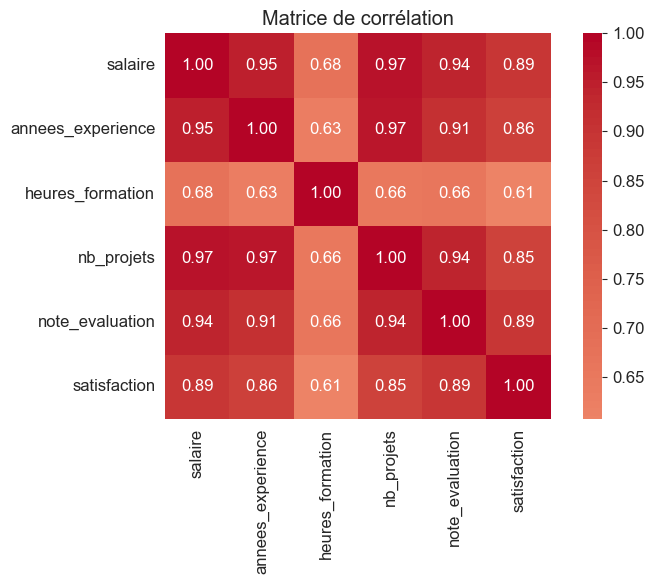

Top corrélations avec le salaire :
  nb_projets                : r = +0.974
  annees_experience         : r = +0.947
→ Logique : plus d'expérience et de projets = salaire plus élevé

Crosstab département × type_contrat :
type_contrat    Contractuel  Permanent
departement                           
Données                   2          9
Développement             2         12
Infrastructure            1          9
Marketing                 2          5

Plus de contractuels : Données (2)


In [10]:
# a) Matrice de corrélation + heatmap (2 pts)
cols_corr = ['salaire', 'annees_experience', 'heures_formation', 'nb_projets', 'note_evaluation', 'satisfaction']
corr = df[cols_corr].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Matrice de corrélation')
plt.tight_layout()
plt.show()

# b) Top corrélations avec salaire (1 pt)
corr_salaire = corr['salaire'].drop('salaire').abs().sort_values(ascending=False)
print(f"Top corrélations avec le salaire :")
for var, val in corr_salaire.head(2).items():
    print(f"  {var:25} : r = {corr.loc['salaire', var]:+.3f}")
print("→ Logique : plus d'expérience et de projets = salaire plus élevé")

# c) Crosstab (2 pts)
cross = pd.crosstab(df['departement'], df['type_contrat'])
print(f"\nCrosstab département × type_contrat :")
print(cross)
print(f"\nPlus de contractuels : {cross['Contractuel'].idxmax()} ({cross['Contractuel'].max()})")

---
## Q4 — Analyse complète (12 pts)
### 4.1 Dashboard (6 pts)

/var/folders/8z/3v_z80_10qq6rtk0_b4cbx200000gn/T/ipykernel_15080/1111332454.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='departement', y='salaire', ax=axes[0,1], palette='Set2')
/var/folders/8z/3v_z80_10qq6rtk0_b4cbx200000gn/T/ipykernel_15080/1111332454.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.barplot(data=df, x='departement', y='salaire', ax=axes[1,0], palette='Set2', ci=95)
/var/folders/8z/3v_z80_10qq6rtk0_b4cbx200000gn/T/ipykernel_15080/1111332454.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='departement', y='salaire', ax=axes[1,0], palette='Set2', ci=95)


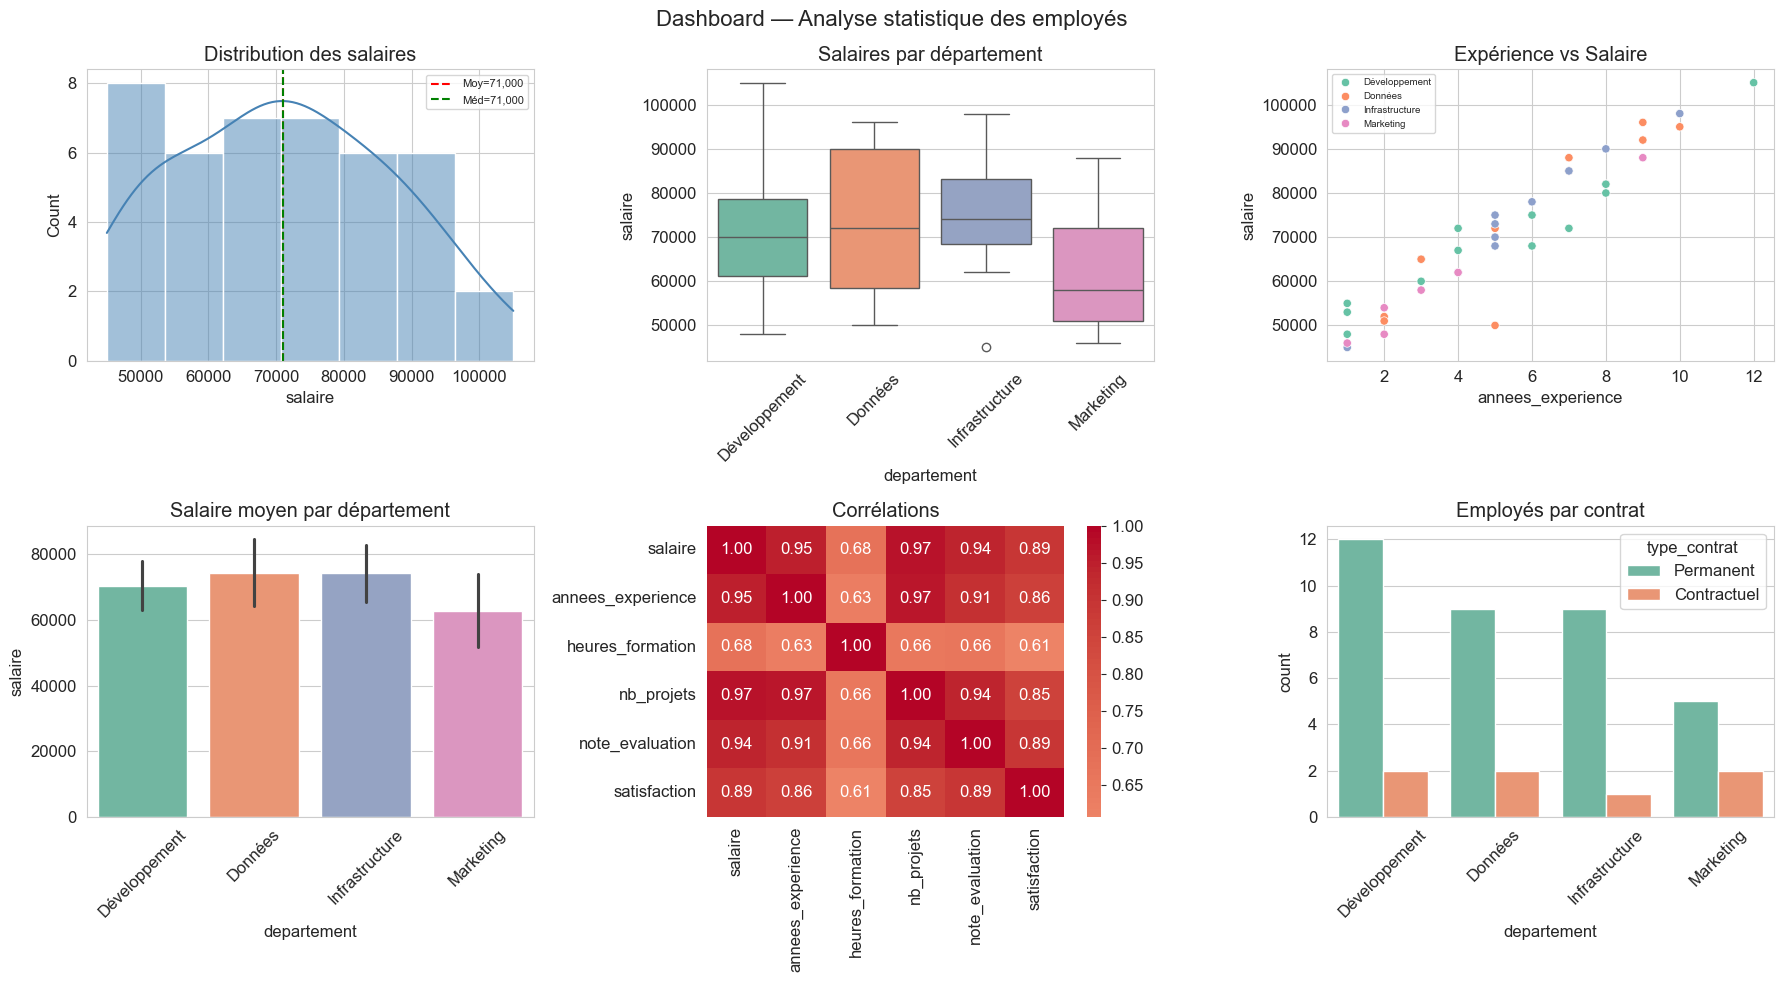

Dashboard sauvegardé : dashboard_stats.png


In [11]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Histogramme + KDE
sns.histplot(data=df, x='salaire', kde=True, ax=axes[0,0], color='steelblue')
axes[0,0].axvline(x=df['salaire'].mean(), color='red', linestyle='--', label=f"Moy={df['salaire'].mean():,.0f}")
axes[0,0].axvline(x=df['salaire'].median(), color='green', linestyle='--', label=f"Méd={df['salaire'].median():,.0f}")
axes[0,0].set_title('Distribution des salaires')
axes[0,0].legend(fontsize=8)

# 2. Boxplot par département
sns.boxplot(data=df, x='departement', y='salaire', ax=axes[0,1], palette='Set2')
axes[0,1].set_title('Salaires par département')
axes[0,1].tick_params(axis='x', rotation=45)

# 3. Scatter expérience vs salaire
sns.scatterplot(data=df, x='annees_experience', y='salaire', hue='departement', ax=axes[0,2], palette='Set2')
axes[0,2].set_title('Expérience vs Salaire')
axes[0,2].legend(fontsize=7)

# 4. Barplot salaire moyen
sns.barplot(data=df, x='departement', y='salaire', ax=axes[1,0], palette='Set2', ci=95)
axes[1,0].set_title('Salaire moyen par département')
axes[1,0].tick_params(axis='x', rotation=45)

# 5. Heatmap
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1,1], center=0)
axes[1,1].set_title('Corrélations')

# 6. Countplot
sns.countplot(data=df, x='departement', hue='type_contrat', ax=axes[1,2], palette='Set2')
axes[1,2].set_title('Employés par contrat')
axes[1,2].tick_params(axis='x', rotation=45)

plt.suptitle('Dashboard — Analyse statistique des employés', fontsize=16)
plt.tight_layout()
plt.savefig('dashboard_stats.png', dpi=150)
plt.show()
print("Dashboard sauvegardé : dashboard_stats.png")

### 4.2 Conclusions (6 pts)

**1. Profil typique (2 pts) :**

L'employé typique a un salaire médian d'environ 72 000$, une expérience médiane de 5 ans, travaille au département Développement (le plus représenté) et est en contrat permanent.

**2. Inégalités salariales (2 pts) :**

Oui, il y a des inégalités. Le département Données a le salaire moyen le plus élevé (~80k), suivi de Infrastructure (~75k), Développement (~70k) et Marketing (~58k). Le CV du Marketing est plus élevé, indiquant une plus grande hétérogénéité. L'IQR du département Données est le plus grand.

**3. Recommandation (2 pts) :**

Les deux facteurs les plus corrélés au salaire sont l'expérience et le nombre de projets. Un nouvel employé devrait viser le département Données ou Infrastructure, accumuler de l'expérience et participer au maximum de projets pour maximiser son salaire à moyen terme.

---
*CORRIGÉ — FSCI 6222 — Université de Moncton — Été 2026*